# LankaEcon – Phase 2: Exploratory Data Analysis & Regional Comparison

This notebook explores Sri Lanka's macro and commodity price data built in Phase 1:

1. **Data coverage & caveats**: what each series can and cannot support
2. **Macro trends**: inflation (cleaned CPI) and the LKR/USD exchange rate
3. **Commodity price trends**: rice, coconut, sugar and vegetables
4. **Seasonality**: vegetable and rice patterns around the Maha / Yala cycles
5. **The 2022 crisis**: shock and recovery
6. **Regional comparison**: prices across 38 WFP markets and 25 districts
7. **Wholesale vs retail margins**: CBSL daily market data

Data caveats from `PHASE1_NOTES.md` are kept explicit throughout:
- inflation comes from different indices over time (`inflation_source`)
- the raw IMF CPI break in 2024-09 → 2025-08 (`cpi_break_flag`) is *not* used
- extended commodity prices after 2025-09 are level-adjusted CBSL data (`source = cbsl_scaled`)
- fuel months spanning a missing revision are flagged `possible_missing_revision`

Figures are also saved to `reports/figures/`.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from statsmodels.tsa.seasonal import STL

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
PROC = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 130, "axes.titleweight": "bold",
                     "figure.figsize": (11, 4.5)})
CRISIS = (pd.Timestamp("2022-01-01"), pd.Timestamp("2023-06-01"))
COVID = (pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-01"))

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

def shade(ax, crisis=True, covid=False):
    if covid:
        ax.axvspan(*COVID, color="grey", alpha=0.10, label="COVID-19 (2020-03 → 2021-12)")
    if crisis:
        ax.axvspan(*CRISIS, color="tab:red", alpha=0.08, label="2022 crisis (2022-01 → 2023-06)")

## 1. Data coverage & caveats

In [2]:
macro = pd.read_csv(PROC / "macro_monthly.csv", parse_dates=["date"], index_col="date")
panel = pd.read_csv(PROC / "analysis_panel_monthly.csv", parse_dates=["date"], index_col="date")
cont = pd.read_csv(PROC / "commodity_prices_continuous_monthly.csv", parse_dates=["date"])
mkt = pd.read_csv(PROC / "commodity_prices_market_monthly.csv", parse_dates=["date"])
cbsl = pd.read_csv(PROC / "cbsl_prices_monthly.csv", parse_dates=["date"])
cbsl["item"] = cbsl["item"].str.replace("(lmp)", "(Imp)", regex=False)
fuel = pd.read_csv(PROC / "fuel_prices_monthly.csv", parse_dates=["date"], keep_default_na=False)
fuel["price_lkr"] = pd.to_numeric(fuel["price_lkr"])

print("Inflation series by source (months):")
src = (macro.dropna(subset=["inflation_yoy_pct"]).reset_index()
            .groupby("inflation_source")["date"].agg(["min", "max", "count"]))
display(src)
print("Months where the RAW IMF YoY is distorted (cpi_break_flag = 1):",
      int(macro["cpi_break_flag"].sum()), "→ not used; official CCPI is used instead")

Inflation series by source (months):


,min,max,count
inflation_source,,,
dcs_ccpi,2023-12-01,2025-10-01,23
imf_ccpi,2025-11-01,2026-08-01,10
imf_ncpi,2000-01-01,2023-11-01,287


Months where the RAW IMF YoY is distorted (cpi_break_flag = 1): 12 → not used; official CCPI is used instead


In [3]:
cov = (cont.groupby("commodity")
           .apply(lambda g: pd.Series({
               "first": g["date"].min().strftime("%Y-%m"),
               "last_wfp": g.loc[g["source"] == "wfp", "date"].max().strftime("%Y-%m"),
               "last": g["date"].max().strftime("%Y-%m"),
               "months": len(g),
               "cbsl_scaled_months": int((g["source"] == "cbsl_scaled").sum())}))
           .sort_values("months", ascending=False))
display(cov)
ends_early = cov[cov["last"] < "2026-01"].index.tolist()
print("Items NOT extended past WFP (end 2025-09):", ends_early)
print("\nFuel months flagged possible_missing_revision:")
display(fuel[fuel["flag"] != ""].groupby("product")["date"].agg(["min", "max", "count"]))

,first,last_wfp,last,months,cbsl_scaled_months
commodity,,,,,
Rice (white),2006-07,2025-09,2026-11,234,14
Onions (imported),2020-01,2025-09,2026-11,71,14
Eggs,2020-01,2025-09,2026-11,69,14
Snake gourd,2020-01,2025-09,2026-11,63,14
Potatoes (local),2020-01,2025-09,2026-11,63,14
Beans,2020-01,2025-09,2026-11,63,14
Tomatoes,2020-01,2025-09,2026-11,63,14
Eggplants,2020-01,2025-09,2026-11,63,14
Coconut,2020-01,2025-09,2026-11,63,14


Items NOT extended past WFP (end 2025-09): ['Pumpkin', 'Fish (dry, katta)', 'Fish (dry, sprats)', 'Onions (red, local)', 'Bananas']

Fuel months flagged possible_missing_revision:


,min,max,count
product,,,
auto_diesel,2026-03-01,2026-03-01,1
kerosene,2026-03-01,2026-10-01,7
petrol_92,2026-03-01,2026-10-01,7
petrol_95,2026-03-01,2026-10-01,8
super_diesel,2026-03-01,2026-10-01,8


**Coverage notes**
- Only **white rice** (from 2006) and **wheat flour** have long monthly histories. Most items start in 2020, have a gap in 2021–22, and are dense from 2023.
- Items in `ends_early` failed the Phase 1 WFP–CBSL agreement test and stop in 2025-09.
- **Sugar** is not in the continuous file because WFP sugar ends in 2022-06. Below, WFP sugar (to 2022) is joined to CBSL `Sugar (White)` retail (from 2023), which is not level-adjusted.
- Fuel months flagged `possible_missing_revision` are excluded from the analysis.

## 2. Macro trends: inflation and the exchange rate

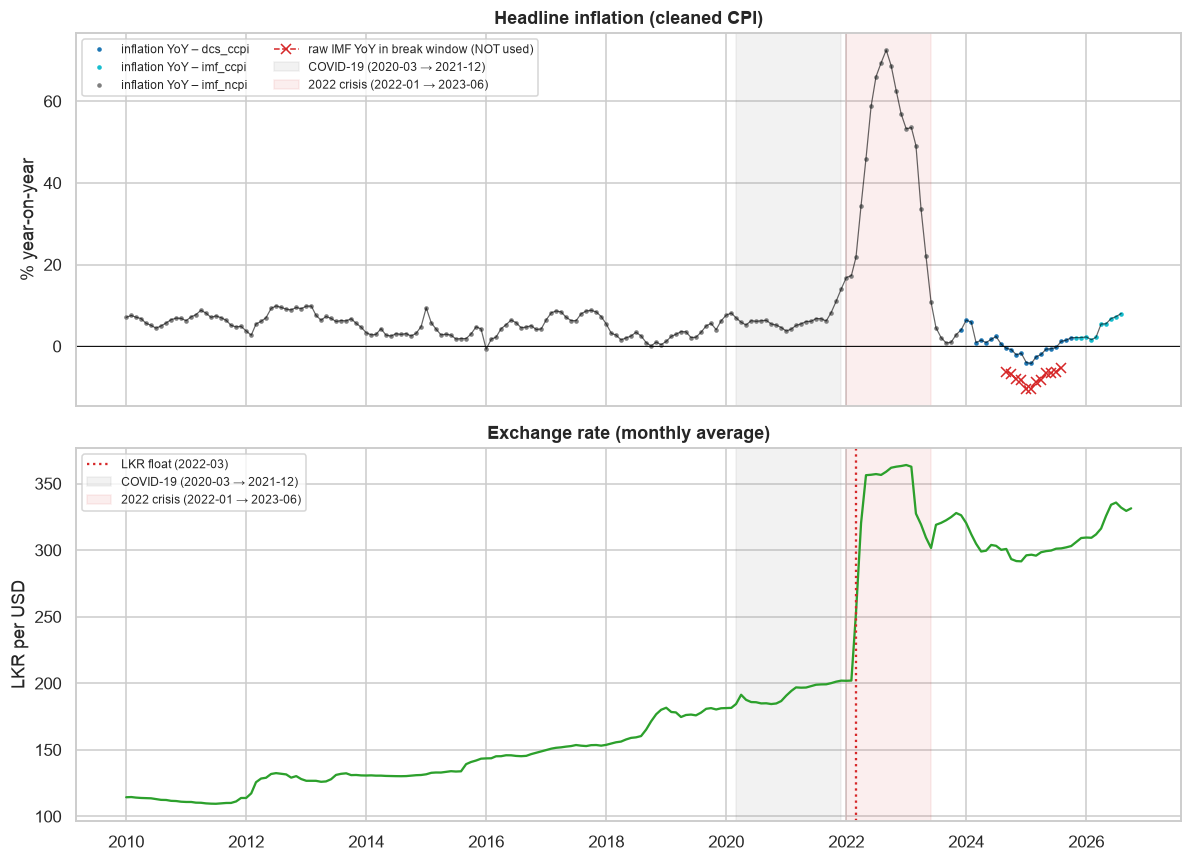

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
m = macro.loc["2010":]
colors = {"imf_ncpi": "tab:grey", "dcs_ccpi": "tab:blue", "imf_ccpi": "tab:cyan"}
for s, g in m.groupby("inflation_source"):
    ax1.plot(g.index, g["inflation_yoy_pct"], ".", ms=4, color=colors[s], label=f"inflation YoY – {s}")
ax1.plot(m.index, m["inflation_yoy_pct"], color="black", lw=0.8, alpha=0.6)
raw = m.loc[m["cpi_break_flag"] == 1, "imf_inflation_yoy_raw"]
ax1.plot(raw.index, raw, "x--", color="tab:red", lw=1, label="raw IMF YoY in break window (NOT used)")
ax1.axhline(0, color="black", lw=0.6)
shade(ax1, covid=True)
ax1.set_ylabel("% year-on-year"); ax1.set_title("Headline inflation (cleaned CPI)")
ax1.legend(fontsize=8, ncol=2)

ax2.plot(m.index, m["lkr_per_usd"], color="tab:green")
ax2.axvline(pd.Timestamp("2022-03-01"), color="tab:red", ls=":", label="LKR float (2022-03)")
shade(ax2, covid=True)
ax2.set_ylabel("LKR per USD"); ax2.set_title("Exchange rate (monthly average)")
ax2.legend(fontsize=8)
fig.tight_layout(); save(fig, "01_inflation_fx")

In [5]:
fx = macro["lkr_per_usd"]
infl = macro["inflation_yoy_pct"]
summary = pd.Series({
    "Peak inflation (% YoY)": infl.max(),
    "Peak inflation month": infl.idxmax().strftime("%Y-%m"),
    "Lowest inflation since 2023 (% YoY)": infl.loc["2023":].min(),
    "Lowest month": infl.loc["2023":].idxmin().strftime("%Y-%m"),
    "Latest inflation (% YoY)": infl.dropna().iloc[-1],
    "Latest month": infl.dropna().index[-1].strftime("%Y-%m"),
    "LKR/USD Feb-2022 (pre-float)": fx["2022-02-01"],
    "LKR/USD peak": fx.loc["2022":].max(),
    "LKR/USD peak month": fx.loc["2022":].idxmax().strftime("%Y-%m"),
    "Depreciation to peak (%)": (fx.loc["2022":].max() / fx["2022-02-01"] - 1) * 100,
    "LKR/USD latest": fx.dropna().iloc[-1],
    "Recovery from peak (%)": (1 - fx.dropna().iloc[-1] / fx.loc["2022":].max()) * 100,
}, dtype=object)
display(summary.to_frame("value"))

,value
Peak inflation (% YoY),72.54
Peak inflation month,2022-09
Lowest inflation since 2023 (% YoY),-4.20
Lowest month,2025-02
Latest inflation (% YoY),8.02
Latest month,2026-08
LKR/USD Feb-2022 (pre-float),202.01
LKR/USD peak,363.94
LKR/USD peak month,2023-01
Depreciation to peak (%),80.17


## 3. Commodity price trends

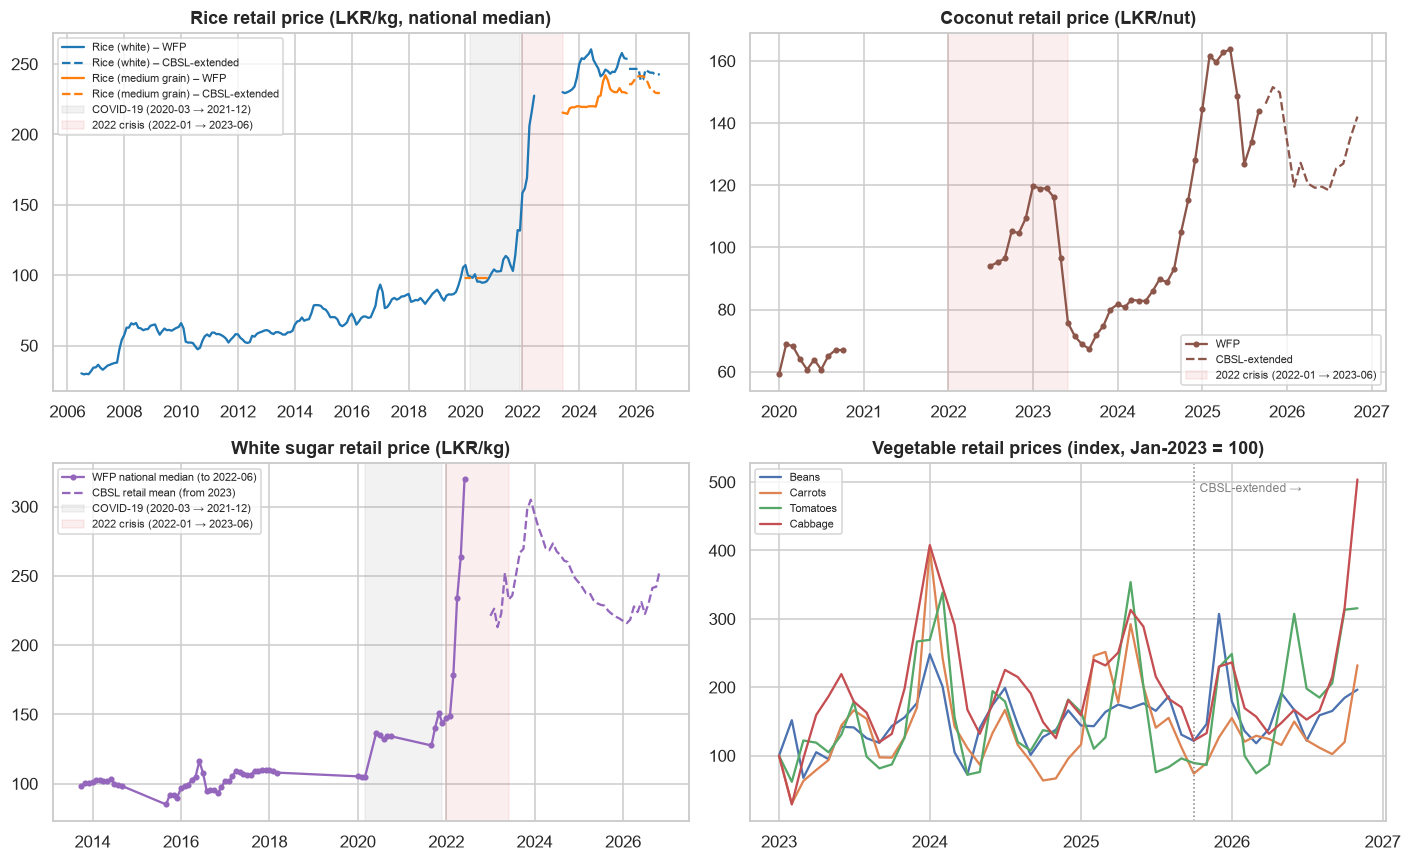

In [6]:
def series(commodity):
    # Regular monthly index, so missing months show as gaps rather than straight lines
    return cont[cont["commodity"] == commodity].set_index("date").asfreq("MS")

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
# Rice: long history
ax = axes[0, 0]
for name, c in [("Rice (white)", "tab:blue"), ("Rice (medium grain)", "tab:orange")]:
    s = series(name)
    ax.plot(s.index, s["price_lkr"].where(s["source"] == "wfp"), color=c, label=f"{name} – WFP")
    ax.plot(s.index, s["price_lkr"].where(s["source"] == "cbsl_scaled"), color=c, ls="--",
            label=f"{name} – CBSL-extended")
shade(ax, covid=True); ax.set_title("Rice retail price (LKR/kg, national median)"); ax.legend(fontsize=7)

# Coconut
ax = axes[0, 1]
s = series("Coconut")
ax.plot(s.index, s["price_lkr"].where(s["source"] == "wfp"), "o-", ms=3, color="tab:brown", label="WFP")
ax.plot(s.index, s["price_lkr"].where(s["source"] == "cbsl_scaled"), "--", color="tab:brown", label="CBSL-extended")
shade(ax); ax.set_title("Coconut retail price (LKR/nut)"); ax.legend(fontsize=7)

# Sugar: WFP to 2022 + CBSL retail mean from 2023 (not level-adjusted)
ax = axes[1, 0]
ws = panel["price_sugar"].dropna()
cs = (cbsl[(cbsl["item"] == "Sugar (White)") & (cbsl["pricetype"] == "Retail")]
        .groupby("date")["price_lkr"].mean())
ax.plot(ws.index, ws, "o-", ms=3, color="tab:purple", label="WFP national median (to 2022-06)")
ax.plot(cs.index, cs, color="tab:purple", ls="--", label="CBSL retail mean (from 2023)")
shade(ax, covid=True); ax.set_title("White sugar retail price (LKR/kg)"); ax.legend(fontsize=7)

# Vegetables (indexed)
ax = axes[1, 1]
for name in ["Beans", "Carrots", "Tomatoes", "Cabbage"]:
    s = series(name).loc["2023":, "price_lkr"]
    ax.plot(s.index, s / s.iloc[0] * 100, label=name)
ax.axvline(pd.Timestamp("2025-10-01"), color="grey", ls=":", lw=1)
ax.text(pd.Timestamp("2025-10-15"), ax.get_ylim()[1] * 0.92, "CBSL-extended →", fontsize=8, color="grey")
ax.set_title("Vegetable retail prices (index, Jan-2023 = 100)"); ax.legend(fontsize=7)
for a in axes.flat:
    a.xaxis.set_major_locator(mdates.YearLocator(base=2 if a in (axes[0, 0], axes[1, 0]) else 1))
    a.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout(); save(fig, "02_commodity_trends")

In [7]:
key = ["Rice (white)", "Rice (medium grain)", "Coconut", "Lentils", "Onions (imported)", "Potatoes (local)",
       "Beans", "Carrots", "Tomatoes", "Cabbage", "Eggs"]
# Compare 12-month averages, so seasonal swings don't distort the change
# (a Jan-vs-Nov comparison for vegetables would mostly measure the season).
rows = []
for k in key:
    s = series(k)["price_lkr"]
    s23 = s.loc["2023":]
    last12 = s.iloc[-12:]
    rows.append({"commodity": k, "avg_2023": s.loc["2023"].mean(),
                 "avg_last_12m": last12.mean(),
                 "last_12m": f"{last12.index[0]:%Y-%m}..{last12.index[-1]:%Y-%m}",
                 "change_%": (last12.mean() / s.loc["2023"].mean() - 1) * 100,
                 "min_since_2023": s23.min(), "max_since_2023": s23.max(),
                 "max/min (volatility)": s23.max() / s23.min()})
trend = pd.DataFrame(rows).set_index("commodity").sort_values("max/min (volatility)", ascending=False)
display(trend)
print("Note: 2026-11 is a partial month (CBSL reports to 2026-11-25).")
print("Note: WFP cabbage 2023-02 = 48 LKR/kg (between 168 and 161) looks like a data error -> anomaly-detection test case.")

,avg_2023,avg_last_12m,last_12m,change_%,min_since_2023,max_since_2023,max/min (volatility)
commodity,,,,,,,
Cabbage,262.91,361.97,2025-12..2026-11,37.68,48.00,843.95,17.58
Carrots,355.47,432.69,2025-12..2026-11,21.72,97.00,"1,299.20",13.39
Onions (imported),187.78,251.82,2025-12..2026-11,34.10,89.70,606.00,6.76
Tomatoes,309.02,512.29,2025-12..2026-11,65.78,155.00,887.29,5.72
Beans,455.06,616.98,2025-12..2026-11,35.58,242.22,"1,101.12",4.55
Coconut,89.99,128.19,2025-12..2026-11,42.45,67.35,163.75,2.43
Eggs,50.08,38.87,2025-12..2026-11,-22.39,28.30,58.40,2.06
Potatoes (local),370.33,410.28,2025-12..2026-11,10.79,260.00,472.21,1.82
Lentils,329.97,272.68,2025-12..2026-11,-17.36,256.71,377.58,1.47


Note: 2026-11 is a partial month (CBSL reports to 2026-11-25).
Note: WFP cabbage 2023-02 = 48 LKR/kg (between 168 and 161) looks like a data error -> anomaly-detection test case.


,real change: last 12m to 2026-08 vs 2023 avg (%)
Rice (white),0.97
Coconut,39.61
Beans,20.35
Lentils,-20.97


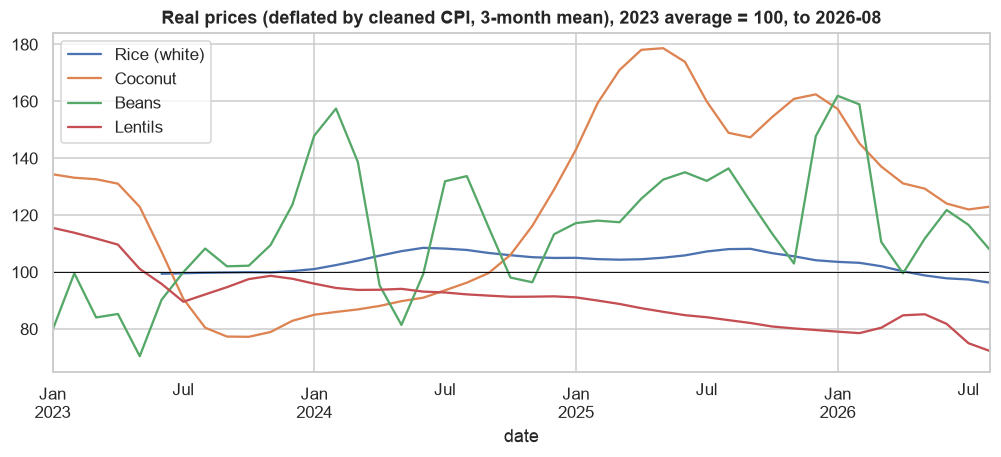

In [8]:
# Real (CPI-deflated) prices: are staples getting more or less affordable?
cpi = macro["cpi_headline_index"].dropna()
real = {}
for k in ["Rice (white)", "Coconut", "Beans", "Lentils"]:
    s = series(k)["price_lkr"]
    real[k] = (s / cpi.reindex(s.index) * cpi["2023-01-01"]).loc["2023":cpi.index.max()]
real = pd.DataFrame(real)
fig, ax = plt.subplots(figsize=(11, 4))
(real.rolling(3, min_periods=1).mean() / real.loc["2023"].mean() * 100).plot(ax=ax)
ax.axhline(100, color="black", lw=0.6)
ax.set_title(f"Real prices (deflated by cleaned CPI, 3-month mean), 2023 average = 100, to {cpi.index.max():%Y-%m}")
save(fig, "03_real_prices")
rc = (real.iloc[-12:].mean() / real.loc["2023"].mean() - 1) * 100
display(rc.rename(f"real change: last 12m to {cpi.index.max():%Y-%m} vs 2023 avg (%)").to_frame())

## 4. Seasonality: Maha and Yala cycles

Sri Lanka has two cultivation seasons:
- **Maha** (northeast monsoon): sown Sep–Oct, harvested **Jan–Mar**
- **Yala** (southwest monsoon): sown Apr–May, harvested **Aug–Sep**

Up-country vegetables (beans, carrots, cabbage) also depend on monsoon rains in the hill country.

The **CBSL Dambulla wholesale** price is used as the closest available farm-gate proxy. It is dense monthly data from 2023-01 to 2026-11 (about 4 years). Each month's **seasonal index** = price ÷ centred 12-month moving average, averaged by calendar month.

⚠️ About 4 years of data gives a rough seasonal pattern, not a robust estimate. Treat it as indicative.

,peak_month,peak_index,trough_month,trough_index,peak_to_trough_%
Green Chilli,Dec,198.25,May,40.73,386.73
Carrot,Jan,162.04,Oct,40.81,297.10
Tomato,Dec,169.99,Sep,46.46,265.89
Pumpkin,Feb,148.60,Sep,46.44,219.97
Cabbage,Jan,143.83,Oct,50.89,182.65
Snake gourd,Dec,150.60,Jul,69.64,116.24
Brinjal,Dec,147.51,Mar,71.74,105.61
Beans,Dec,132.18,Sep,75.37,75.38
Potato (Local),Jan,121.72,Oct,73.36,65.93
Red Onion (Local),Jun,121.89,Aug,79.49,53.34


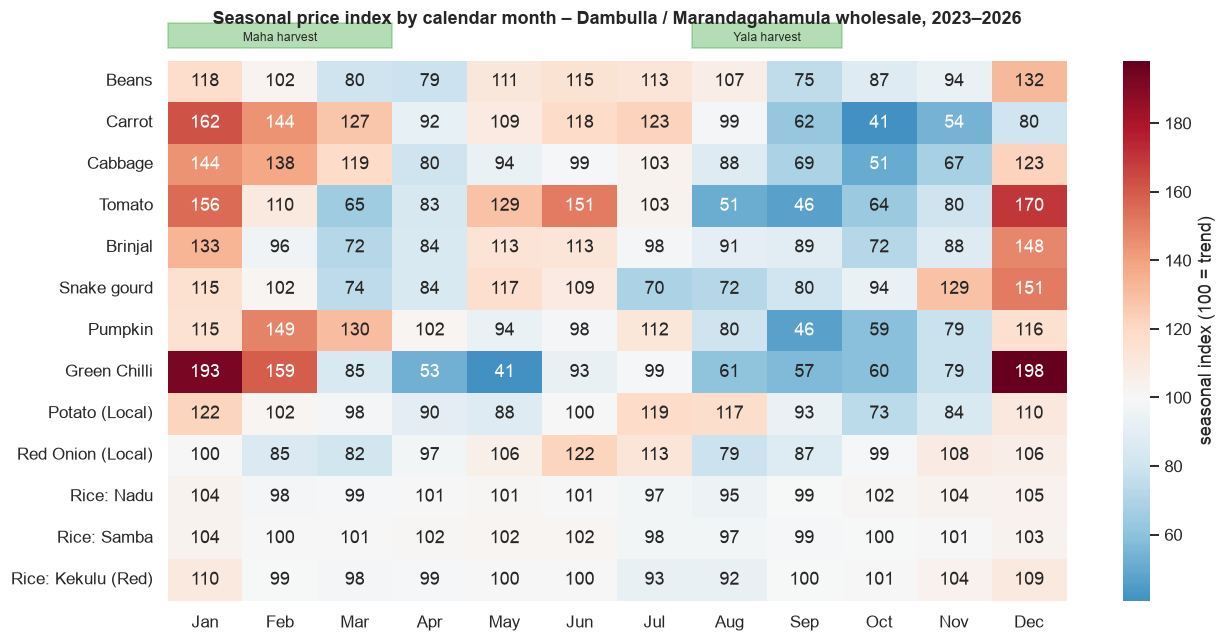

In [9]:
def seasonal_index(s):
    s = s.asfreq("MS").interpolate(limit=2)
    trend = s.rolling(12, center=True, min_periods=12).mean()
    return (s / trend).groupby(s.index.month).mean() * 100

veg = ["Beans", "Carrot", "Cabbage", "Tomato", "Brinjal", "Snake gourd", "Pumpkin",
       "Green Chilli", "Potato (Local)", "Red Onion (Local)", "Big Onion (Local)"]
dam_ws = cbsl[(cbsl["market"] == "Dambulla") & (cbsl["pricetype"] == "Wholesale")]
si = {}
for v in veg:
    s = dam_ws[dam_ws["item"] == v].set_index("date")["price_lkr"].sort_index()
    if s.notna().sum() >= 30:
        si[v] = seasonal_index(s)
# Rice: Marandagahamula is the main paddy/rice wholesale hub
mar = cbsl[(cbsl["market"] == "Marandagahamula") & (cbsl["pricetype"] == "Wholesale")]
for r in ["Nadu", "Samba", "Kekulu (Red)"]:
    s = mar[mar["item"] == r].set_index("date")["price_lkr"].sort_index()
    if s.notna().sum() >= 30:
        si[f"Rice: {r}"] = seasonal_index(s)
si = pd.DataFrame(si).T
si.columns = [pd.Timestamp(2000, m, 1).strftime("%b") for m in si.columns]

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(si, cmap="RdBu_r", center=100, annot=True, fmt=".0f", cbar_kws={"label": "seasonal index (100 = trend)"}, ax=ax)
for x0, x1, lab in [(0, 3, "Maha harvest"), (7, 9, "Yala harvest")]:
    ax.add_patch(plt.Rectangle((x0, -0.9), x1 - x0, 0.6, color="tab:green", alpha=0.35, clip_on=False))
    ax.text((x0 + x1) / 2, -0.55, lab, ha="center", va="center", fontsize=8)
ax.set_title("Seasonal price index by calendar month – Dambulla / Marandagahamula wholesale, 2023–2026", pad=24)
fig.tight_layout(); save(fig, "04_seasonality_heatmap")
peak = pd.DataFrame({"peak_month": si.idxmax(axis=1), "peak_index": si.max(axis=1),
                     "trough_month": si.idxmin(axis=1), "trough_index": si.min(axis=1)})
peak["peak_to_trough_%"] = (peak["peak_index"] / peak["trough_index"] - 1) * 100
display(peak.sort_values("peak_to_trough_%", ascending=False))

,share of variance (%)
seasonal,54.86
trend,11.23
residual,33.91


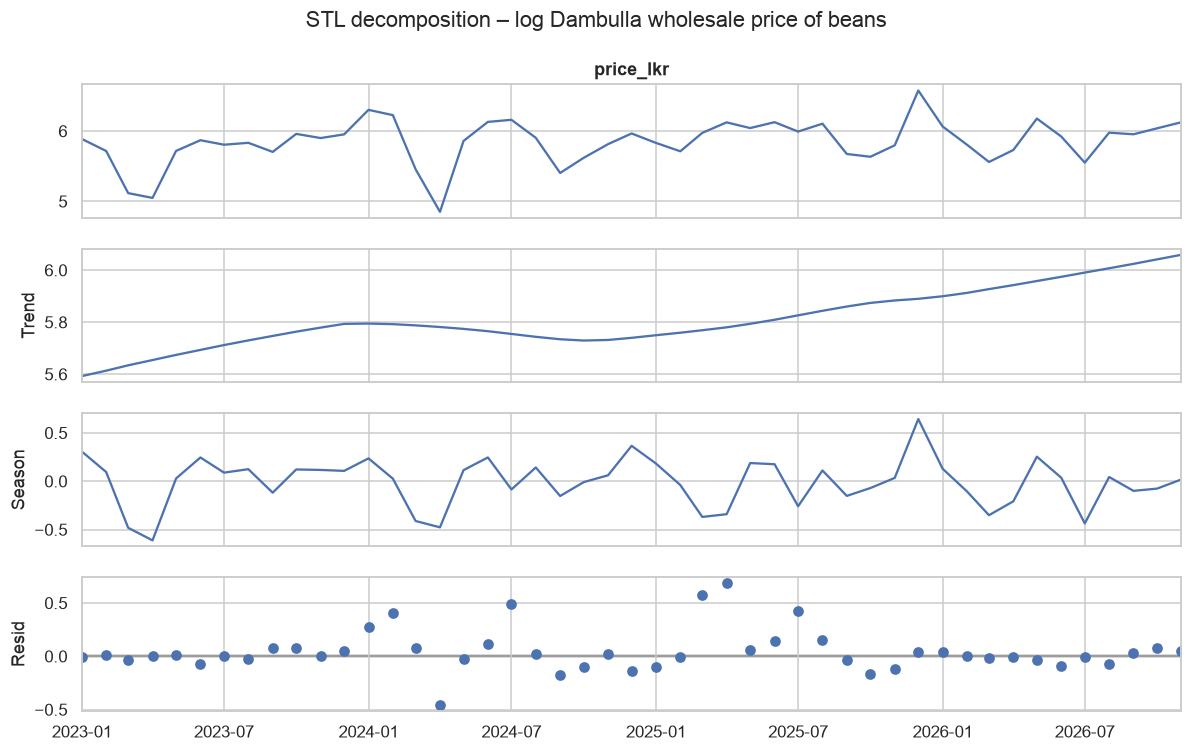

In [10]:
# STL decomposition for one volatile vegetable (beans) to show trend vs seasonal vs irregular
s = dam_ws[dam_ws["item"] == "Beans"].set_index("date")["price_lkr"].sort_index().asfreq("MS").interpolate(limit=2)
res = STL(np.log(s.dropna()), period=12, robust=True).fit()
fig = res.plot(); fig.set_size_inches(11, 7)
fig.suptitle("STL decomposition – log Dambulla wholesale price of beans", y=1.01)
save(fig, "05_stl_beans")
var = pd.Series({"seasonal": res.seasonal.var(), "trend": res.trend.var(), "residual": res.resid.var()})
display((var / var.sum() * 100).rename("share of variance (%)").to_frame())

## 5. The 2022 crisis: shock and recovery

The crisis followed foreign-exchange shortages, the LKR float in March 2022, fuel and fertiliser shortages, and the debt default in April 2022. Only **white rice** and **wheat flour** have unbroken monthly WFP data through 2021–2023. They are compared with the cleaned CPI and LKR/USD, all indexed to **Jan-2021 = 100**.

,peak_index (2021-01=100),peak_month,latest_index,latest_month,latest_vs_peak_%
series,,,,,
CPI (cleaned),190.53,2024-01,198.22,2026-08,4.04
LKR per USD,190.78,2023-01,173.73,2026-10,-8.94
Rice (white),250.21,2024-06,233.24,2026-11,-6.78
Wheat flour,302.75,2022-06,302.75,2022-06,0.00


Note: WFP wheat flour ends 2022-06, still rising, so its peak and recovery cannot be observed.


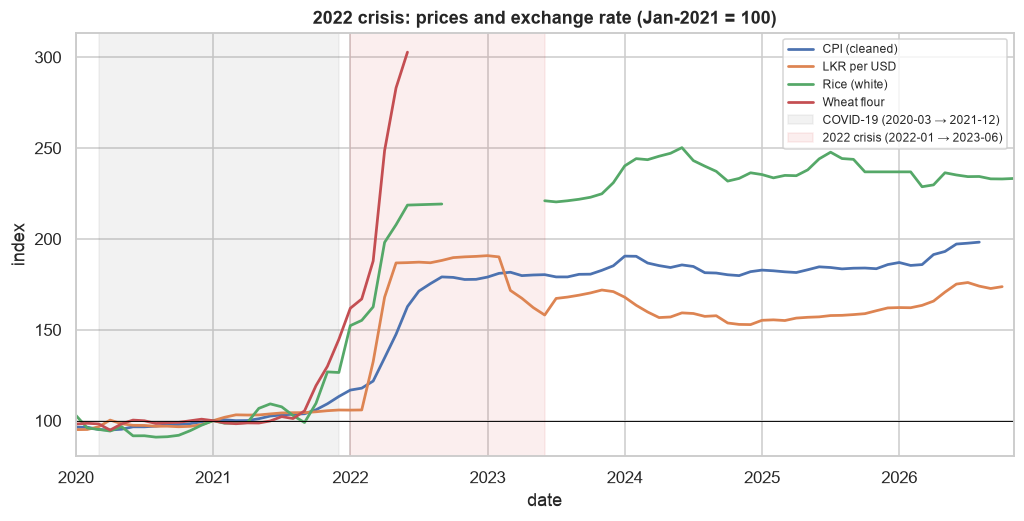

In [11]:
crisis = pd.DataFrame({
    "CPI (cleaned)": macro["cpi_headline_index"],
    "LKR per USD": macro["lkr_per_usd"],
    "Rice (white)": series("Rice (white)")["price_lkr"],
    "Wheat flour": panel["price_wheat_flour"],
}).loc["2020-01-01":]
crisis = crisis.interpolate(limit=3, limit_area="inside")
idx = crisis / crisis.loc["2021-01-01"] * 100

fig, ax = plt.subplots(figsize=(11, 5))
idx.plot(ax=ax, lw=1.8)
shade(ax, covid=True)
ax.axhline(100, color="black", lw=0.6)
ax.set_title("2022 crisis: prices and exchange rate (Jan-2021 = 100)"); ax.set_ylabel("index")
ax.legend(fontsize=8)
save(fig, "06_crisis_index")

rows = []
for c in idx.columns:
    s = idx[c].dropna()
    pk = s.loc["2021":"2024"].idxmax()
    rows.append({"series": c, "peak_index (2021-01=100)": s[pk], "peak_month": pk.strftime("%Y-%m"),
                 "latest_index": s.iloc[-1], "latest_month": s.index[-1].strftime("%Y-%m"),
                 "latest_vs_peak_%": (s.iloc[-1] / s[pk] - 1) * 100})
display(pd.DataFrame(rows).set_index("series"))
print("Note: WFP wheat flour ends 2022-06, still rising, so its peak and recovery cannot be observed.")

,Rice (white) USD/kg,Wheat flour USD/kg,World rice USD/kg,World wheat USD/kg
date,,,,
2021-06-01,0.57,0.47,0.46,0.24
2022-06-01,0.64,0.80,0.43,0.40
2022-09-01,0.67,NaN,0.43,0.35
2023-06-01,0.76,NaN,0.49,0.28
2024-06-01,0.86,NaN,0.61,0.20


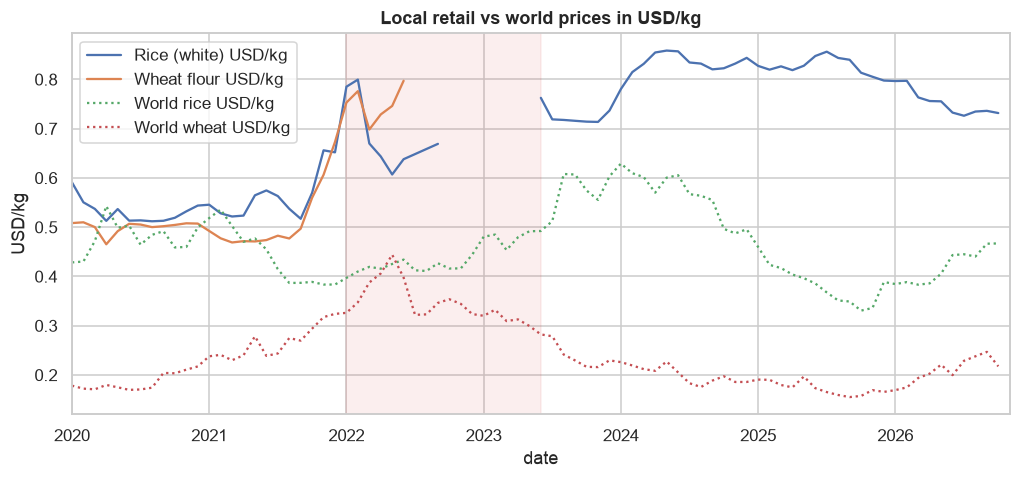

In [12]:
# In USD terms, local food prices moved much less: the shock was mostly currency
usd = pd.DataFrame({
    "Rice (white) USD/kg": series("Rice (white)")["price_lkr"] / macro["lkr_per_usd"],
    "Wheat flour USD/kg": panel["price_wheat_flour"] / macro["lkr_per_usd"],
    "World rice USD/kg": macro["world_rice_usd_mt"] / 1000,
    "World wheat USD/kg": macro["world_wheat_usd_mt"] / 1000,
}).loc["2020-01-01":].interpolate(limit=3, limit_area="inside")
fig, ax = plt.subplots(figsize=(11, 4.5))
usd.plot(ax=ax, style=["-", "-", ":", ":"])
shade(ax)
ax.set_title("Local retail vs world prices in USD/kg"); ax.set_ylabel("USD/kg")
save(fig, "07_crisis_usd")
display(usd.loc[["2021-06-01", "2022-06-01", "2022-09-01", "2023-06-01", "2024-06-01"]].round(3))

## 6. Regional comparison: markets and districts

WFP data for **2023-01 → 2025-09** covers 38 retail markets in all 9 provinces with coordinates. For each market, commodity and month, the **relative price** = market price ÷ national median for that commodity and month. Averaging over commodities and months gives a market price level, where 1.00 is the national median.

Fish is analysed separately, because coastal and inland markets differ structurally.

,commodities
group,
coconut,[Coconut]
fish,"[Fish (dry, katta), Fish (dry, sprats), Fish (..."
other,"[Meat (chicken, fresh), Oil (coconut), Cowpeas..."
rice,"[Rice (medium grain), Rice (white)]"
vegetables & fruits,"[Bananas, Cabbage, Carrots, Eggplants, Onions ..."


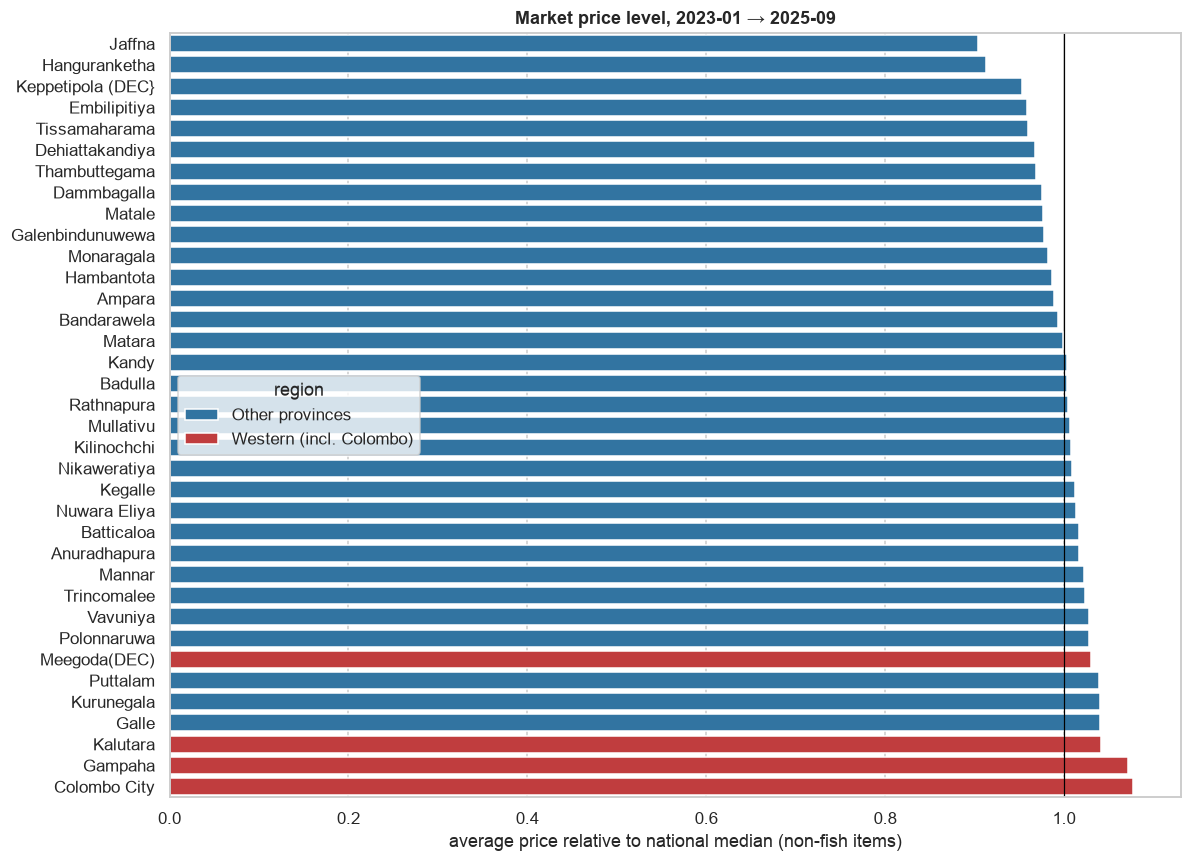

In [13]:
r = mkt[(mkt["date"] >= "2023-01-01") & (mkt["pricetype"] == "Retail")
        & ~mkt["market"].str.contains("Peliyagoda")].copy()
r["rel"] = r["price_lkr"] / r.groupby(["date", "commodity"])["price_lkr"].transform("median")
r["group"] = np.select(
    [r["commodity"].eq("Coconut"), r["commodity"].str.startswith("Rice"),
     r["commodity"].str.startswith("Fish"), r["category"].eq("vegetables and fruits")],
    ["coconut", "rice", "fish", "vegetables & fruits"], "other")
display(r.groupby("group")["commodity"].unique().to_frame("commodities"))
non_fish = r[r["group"] != "fish"]
market_level = (non_fish.groupby(["market", "district", "province", "latitude", "longitude"])["rel"]
                        .agg(["mean", "count"]).reset_index().sort_values("mean"))
market_level["region"] = np.where(market_level["province"] == "Western", "Western (incl. Colombo)", "Other provinces")

fig, ax = plt.subplots(figsize=(11, 8))
pal = {"Western (incl. Colombo)": "tab:red", "Other provinces": "tab:blue"}
sns.barplot(data=market_level, y="market", x="mean", hue="region", dodge=False, palette=pal, ax=ax)
ax.axvline(1, color="black", lw=0.8)
ax.set_xlabel("average price relative to national median (non-fish items)")
ax.set_title("Market price level, 2023-01 → 2025-09"); ax.set_ylabel("")
fig.tight_layout(); save(fig, "08_market_price_level")

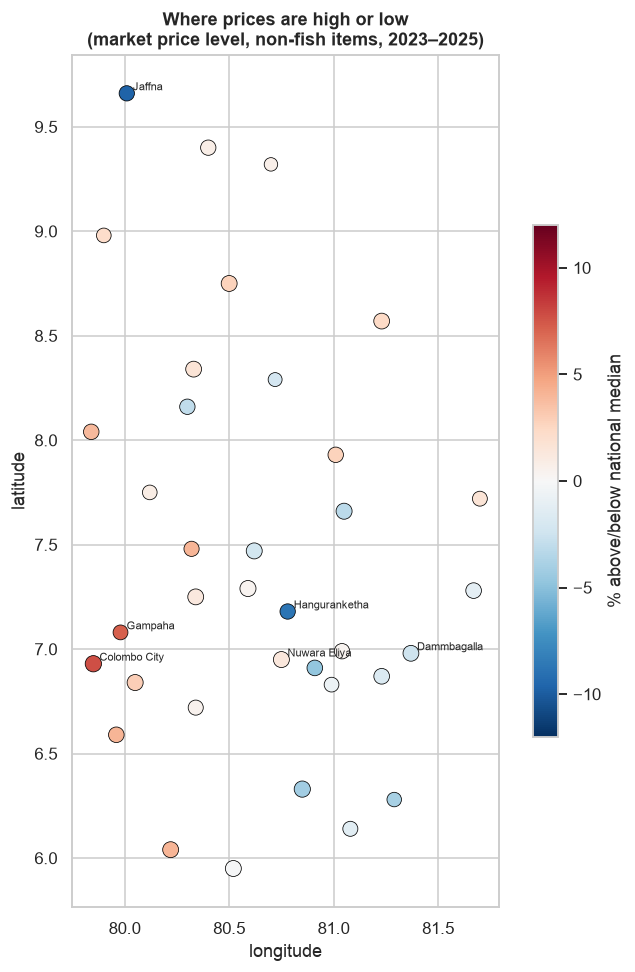

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 9))
sc = ax.scatter(market_level["longitude"], market_level["latitude"], c=(market_level["mean"] - 1) * 100,
                s=market_level["count"] / 6, cmap="RdBu_r", vmin=-12, vmax=12, edgecolor="black", lw=0.5)
for _, t in market_level.iterrows():
    if abs(t["mean"] - 1) > 0.05 or t["market"] in ("Colombo City", "Jaffna", "Nuwara Eliya", "Dammbagalla"):
        ax.annotate(t["market"], (t["longitude"], t["latitude"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
plt.colorbar(sc, ax=ax, label="% above/below national median", shrink=0.6)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_aspect("equal")
ax.set_title("Where prices are high or low\n(market price level, non-fish items, 2023–2025)")
fig.tight_layout(); save(fig, "09_price_map")

group,vegetables & fruits,rice,coconut,fish,other
province,,,,,
Central,-4.40,0.50,6.10,1.30,-0.90
Uva,-3.60,0.20,3.70,-0.20,-0.50
Sabaragamuwa,-1.90,0.80,6.40,5.10,-0.80
Northern,-1.40,-0.70,-16.20,-4.70,2.30
Southern,-1.20,0.50,5.90,2.30,0.40
North Central,0.80,-0.10,-7.40,0.80,-0.50
Eastern,0.90,-0.20,-8.80,2.60,-0.70
North Western,4.60,0.70,-0.70,-5.40,1.80
Western,7.40,-0.10,15.00,5.00,3.10


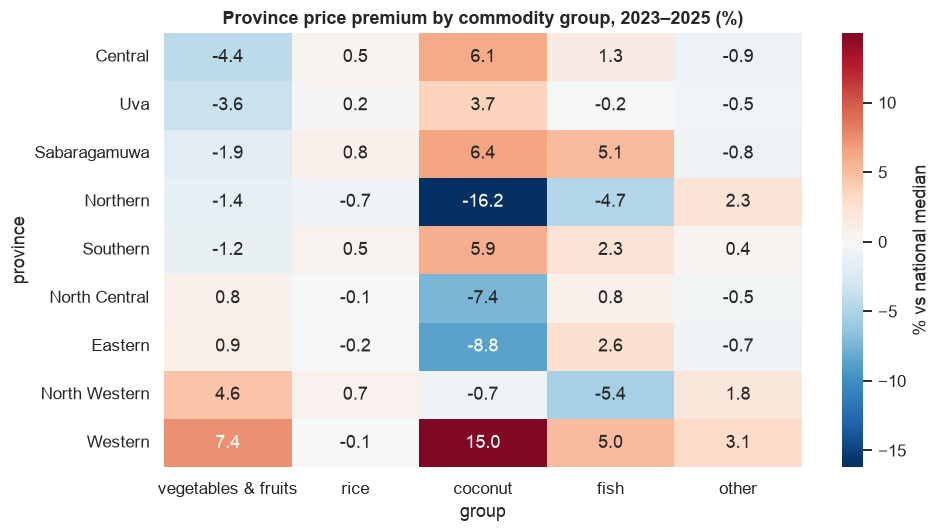

In [15]:
# Province x commodity group
prov = (r.groupby(["province", "group"])["rel"].mean().unstack() - 1) * 100
prov = prov[["vegetables & fruits", "rice", "coconut", "fish", "other"]].sort_values("vegetables & fruits")
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(prov, cmap="RdBu_r", center=0, annot=True, fmt=".1f", cbar_kws={"label": "% vs national median"}, ax=ax)
ax.set_title("Province price premium by commodity group, 2023–2025 (%)")
fig.tight_layout(); save(fig, "10_province_heatmap")
display(prov.round(1))

In [16]:
# Colombo / Western vs the rest, per commodity
r["is_west"] = r["province"] == "Western"
r["is_colombo"] = r["district"] == "Colombo"
spread = pd.DataFrame({
    "Colombo district vs national (%)": (r[r["is_colombo"]].groupby("commodity")["rel"].mean() - 1) * 100,
    "Western vs other provinces (%)": (r[r["is_west"]].groupby("commodity")["rel"].mean()
                                        / r[~r["is_west"]].groupby("commodity")["rel"].mean() - 1) * 100,
    "Northern vs national (%)": (r[r["province"] == "Northern"].groupby("commodity")["rel"].mean() - 1) * 100,
}).dropna().sort_values("Western vs other provinces (%)")
display(spread.round(1))
print("Median Western premium across commodities: %.1f%%" % spread["Western vs other provinces (%)"].median())

,Colombo district vs national (%),Western vs other provinces (%),Northern vs national (%)
commodity,,,
Beans,-1.20,-3.60,10.30
Fish (skipjack tuna),-6.40,-2.80,-14.80
Carrots,-0.80,-2.60,11.40
Pineapples,7.20,-2.20,15.10
"Fish (dry, katta)",-2.90,-1.90,-0.40
Rice (white),-1.30,-1.00,-1.10
"Meat (chicken, broiler)",0.10,-0.70,10.10
Eggs,-0.80,-0.20,1.80
Rice (medium grain),0.80,0.60,-0.30


Median Western premium across commodities: 4.0%


,average CV across markets (%)
group,
coconut,13.90
rice,5.41
vegetables & fruits,42.30


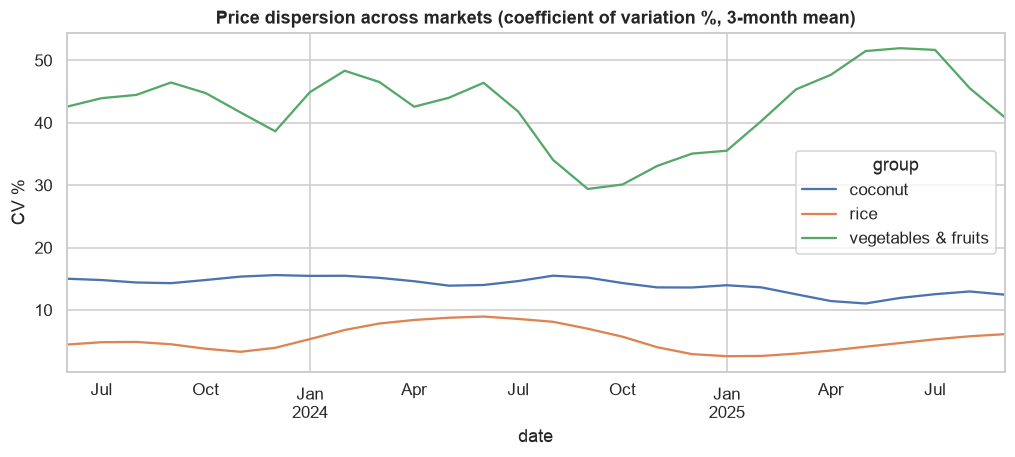

In [17]:
# Market integration: dispersion of prices across markets over time (coefficient of variation)
disp = (r[r["group"].isin(["vegetables & fruits", "rice", "coconut"])]
          .groupby(["date", "group"])["price_lkr"].agg(lambda x: x.std() / x.mean() * 100)
          .unstack())
fig, ax = plt.subplots(figsize=(11, 4))
disp.rolling(3, min_periods=1).mean().plot(ax=ax)
ax.set_title("Price dispersion across markets (coefficient of variation %, 3-month mean)")
ax.set_ylabel("CV %"); save(fig, "11_dispersion")
display(disp.mean().rename("average CV across markets (%)").to_frame())

## 7. Wholesale vs retail margins (CBSL daily price reports)

Monthly averages of the CBSL daily reports, 2023-01 → 2026-11. Three markups are compared:
- **Pettah retail ÷ Pettah wholesale**: within Colombo's main wholesale market
- **Dambulla retail ÷ Dambulla wholesale**: within the main up-country vegetable hub
- **Narahenpita retail ÷ Dambulla wholesale**: farm-hub price → Colombo consumer price (transport, handling, retail)

Rows from CBSL tables with an inferred market layout (`layout_pairs` < 5) are excluded.

In [18]:
daily = pd.read_csv(PROC / "cbsl_daily_prices.csv", parse_dates=["date"])
daily["item"] = daily["item"].str.replace("(lmp)", "(Imp)", regex=False)
daily = daily[daily["layout_pairs"] == 5]
mm = (daily.assign(date=daily["date"].dt.to_period("M").dt.to_timestamp())
            .groupby(["date", "item", "pricetype", "market"])["price_lkr"].mean().unstack(["pricetype", "market"]))

def markup(num, den):
    return (mm[num] / mm[den] - 1) * 100

mk = {}
for name, num, den in [("Pettah RT / Pettah WS", ("Retail", "Pettah"), ("Wholesale", "Pettah")),
                       ("Dambulla RT / Dambulla WS", ("Retail", "Dambulla"), ("Wholesale", "Dambulla")),
                       ("Narahenpita RT / Dambulla WS", ("Retail", "Narahenpita"), ("Wholesale", "Dambulla"))]:
    if num in mm and den in mm:
        mk[name] = markup(num, den)
mk = pd.DataFrame(mk)
by_item = mk.groupby(level="item").median().dropna(how="all")
rice_items = ["Samba", "Nadu", "Kekulu (White)", "Kekulu (Red)"]
by_item["group"] = np.where(by_item.index.isin(rice_items), "rice",
                    np.where(by_item.index.isin(["Coconut (Avg.)"]), "coconut",
                    np.where(by_item.index.isin(["Banana (Sour)", "Papaw", "Pineapple", "Lime"]), "fruit", "vegetables & onions/potato")))
display(by_item.sort_values("Narahenpita RT / Dambulla WS", ascending=False).round(1))

,Pettah RT / Pettah WS,Dambulla RT / Dambulla WS,Narahenpita RT / Dambulla WS,group
item,,,,
Papaw,30.70,30.30,154.60,fruit
Snake gourd,23.20,20.00,135.40,vegetables & onions/potato
Banana (Sour),35.60,28.20,132.50,fruit
Cabbage,33.20,21.20,128.90,vegetables & onions/potato
Lime,20.20,10.00,124.90,fruit
Red Onion (Local),18.80,7.80,106.60,vegetables & onions/potato
Brinjal,18.50,11.80,98.00,vegetables & onions/potato
Pumpkin,42.30,30.90,93.50,vegetables & onions/potato
Green Chilli,16.10,9.60,89.80,vegetables & onions/potato


,Pettah RT / Pettah WS,Dambulla RT / Dambulla WS,Narahenpita RT / Dambulla WS
group,,,
coconut,25.30,4.70,48.20
fruit,25.50,19.10,128.70
rice,7.00,NaN,NaN
vegetables & onions/potato,20.00,11.70,69.30


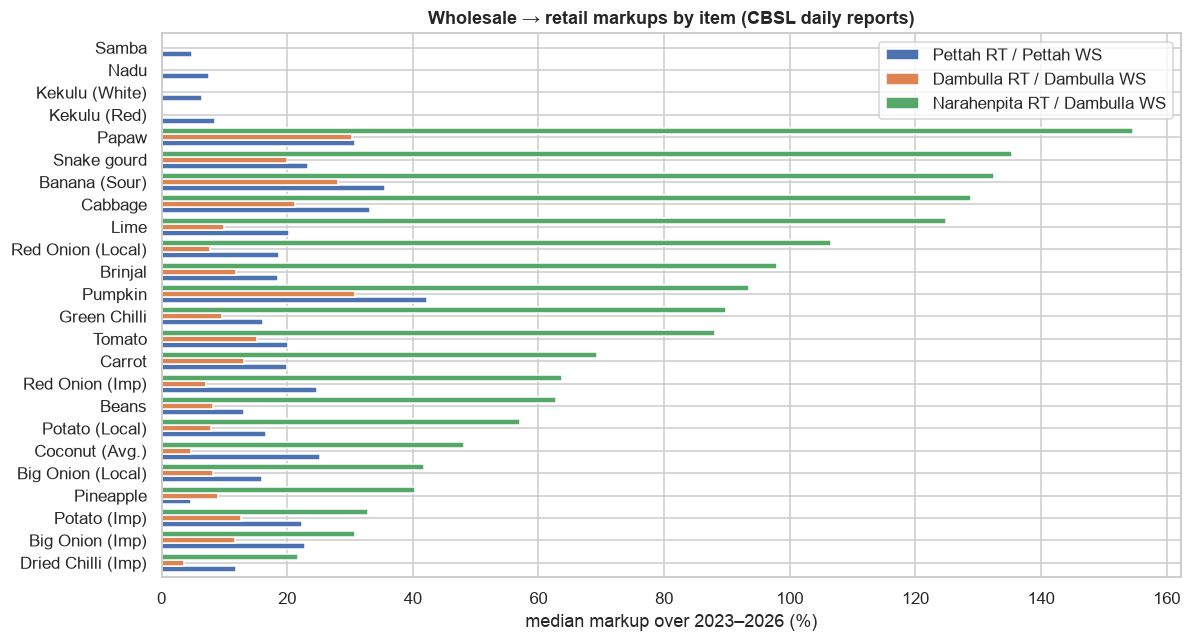

In [19]:
fig, ax = plt.subplots(figsize=(11, 6))
plot_df = by_item.drop(columns="group").sort_values("Narahenpita RT / Dambulla WS")
plot_df.plot.barh(ax=ax, width=0.8)
ax.set_xlabel("median markup over 2023–2026 (%)"); ax.set_ylabel("")
ax.set_title("Wholesale → retail markups by item (CBSL daily reports)")
fig.tight_layout(); save(fig, "12_markups_by_item")
display(by_item.groupby("group").median().round(1))

Median vegetable markup Dambulla WS → Narahenpita RT: 70%
Spearman correlation between wholesale price level and markup: -0.43


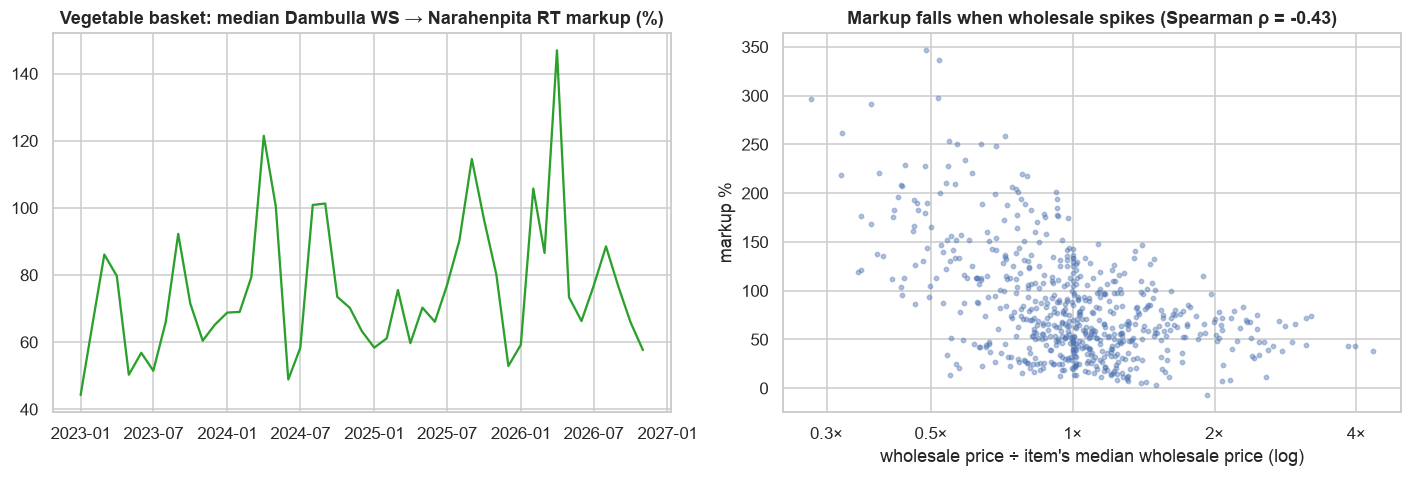

In [20]:
# Are markups stable? Retail prices are stickier than wholesale -> markup % falls when wholesale spikes
veg_items = by_item[by_item["group"] == "vegetables & onions/potato"].index
ws = mm[("Wholesale", "Dambulla")]
rt = mm[("Retail", "Narahenpita")]
veg = pd.DataFrame({"ws": ws, "rt": rt}).loc[(slice(None), list(veg_items)), :].dropna()
veg["markup_%"] = (veg["rt"] / veg["ws"] - 1) * 100
veg["ws_vs_item_median"] = veg["ws"] / veg.groupby(level="item")["ws"].transform("median")
corr = veg[["markup_%", "ws_vs_item_median"]].corr(method="spearman").iloc[0, 1]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
basket = veg.groupby(level="date")["markup_%"].median()
a1.plot(basket.index, basket, color="tab:green")
a1.set_title("Vegetable basket: median Dambulla WS → Narahenpita RT markup (%)")
a2.scatter(veg["ws_vs_item_median"], veg["markup_%"], s=8, alpha=0.4)
a2.set_xscale("log"); a2.set_xlabel("wholesale price ÷ item's median wholesale price (log)")
a2.set_xticks([0.3, 0.5, 1, 2, 4]); a2.set_xticklabels(["0.3×", "0.5×", "1×", "2×", "4×"])
a2.xaxis.set_minor_formatter(plt.NullFormatter())
a2.set_ylabel("markup %"); a2.set_title(f"Markup falls when wholesale spikes (Spearman ρ = {corr:.2f})")
fig.tight_layout(); save(fig, "13_markup_dynamics")
print(f"Median vegetable markup Dambulla WS → Narahenpita RT: {veg['markup_%'].median():.0f}%")
print(f"Spearman correlation between wholesale price level and markup: {corr:.2f}")

## 8. Key findings

**Macro**
- **Inflation:** peaked at **72.5% (Sep-2022)**, fell into deflation (official CCPI low **−4.2%, Feb-2025**; the raw IMF series wrongly showed −10%), and was back at **8.0% by Aug-2026**, rising since Mar-2026.
- **Exchange rate:** LKR/USD went from 202 before the float to a **364 peak (Jan-2023, +80%)**. At **331 (Oct-2026)** it is only 9% off the peak and has weakened again through 2026.

**Commodity prices**
- **Rice:** roughly **2.5×** its Jan-2021 level at the peak (Jun-2024), and has hardly moved since 2023 (max/min 1.14; real price +1% vs 2023).
- **Coconut:** the biggest staple shock after the crisis, from 67 LKR/nut (late 2023) to **164 (Apr-2025)**. In real terms it is still **+40%** vs 2023.
- **Vegetables:** extremely volatile; since 2023 the cabbage max/min ratio is **17.6×** and carrots **13.4×**. Cabbage spiked to ~844 LKR/kg in Nov-2026 (partial month).
- **Lentils and eggs:** cheaper than in 2023 (−17% and −22% nominal).

**Seasonality (indicative, ~4 years of data)**
- **Vegetable peak:** prices peak in **Dec–Jan**, during the northeast monsoon and before the Maha harvest arrives. Tomato 170, green chilli 198, carrot 162 and cabbage 144 (trend = 100).
- **Vegetable trough:** **Sep–Oct**, after the Yala harvest. Carrot 41, cabbage 51, tomato 46.
- **Share of variation:** seasonality explains ~55% of the variance in beans' log wholesale price.
- **Rice:** almost flat (±5–10%), highest in Dec–Jan before the Maha harvest and lowest in August (Yala harvest).

**2022 crisis**
- **Wheat flour:** roughly tripled by Jun-2022, when the WFP data ends.
- **Rice:** kept rising after the crisis and peaked in mid-2024.
- **In USD terms:** local rice went from 0.57 to 0.86 USD/kg (2021→2024) while world rice went from 0.46 to 0.61. The local premium over world prices widened.

**Regional comparison (WFP 2023–2025)**
- **Western Province is most expensive:** vegetables +7.4% and coconut +15% vs the national median. Colombo City is +7.7% and Gampaha +7.2% overall.
- **Cheapest markets:** **Jaffna (−9.7%)** and the up-country producing areas (Hanguranketha −8.8%, Keppetipola −4.7%), which suggests a producer-area discount.
- **Coconut spread:** more than 30 points between the Northern (−16%) and Western (+15%) provinces.
- **Rice is nationally integrated:** every province is within ±1% and the cross-market CV is ~5%. **Vegetables are not** (CV ~42%).

**Wholesale → retail margins (CBSL)**
- **Within-market markups are modest:** Pettah ~20% for vegetables, ~7% for rice; Dambulla ~12%.
- **Farm hub → Colombo consumer** (Dambulla WS → Narahenpita RT): **~70% for vegetables**, ~130% for fruit, ~48% for coconut.
- **Retail prices are sticky:** the markup is negatively related to the wholesale price level (Spearman ρ = −0.43). When wholesale prices crash, retail prices lag and margins widen.

**Implications for the next phases**
- **Forecasting:** model log prices with month-of-year seasonality, crisis/float dummies and `inflation_source` awareness.
- **Anomaly detection:** WFP cabbage 2023-02 (48 LKR/kg) and the Nov-2026 cabbage spike are ready test cases.
- **Pass-through analysis:** use LKR/USD, world prices and fuel, excluding fuel months flagged `possible_missing_revision`.